# Part 2 - Fine-Tuning Stable Diffusion 1.5 on Naruto BLIP Captions (LoRA r=4 vs LoRA r=32)
Run top to bottom on a Kaggle T4 / Colab T4 (Restart & Run All). Everything reported is computed in this notebook.
Set `HF_USER` in the config cell and add an `HF_TOKEN` secret (Kaggle Add-ons > Secrets, or Colab Secrets) to push results.
Human-evaluation numbers come from real rater CSVs (see section 6); until they exist the notebook says so instead of inventing numbers.

In [1]:
# Cell 1 - run information (required)
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip() or "no-git"
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': 'no-git', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [2]:
# Pinned installs (torch itself is preinstalled on Kaggle/Colab). Versions are the ones listed in requirements-p2.txt.
%pip install -q diffusers==0.31.0 transformers==4.46.3 peft==0.13.2 accelerate==1.1.1 datasets==3.1.0 "torchmetrics[image]==1.5.2" torch-fidelity==0.3.0 lpips==0.1.4 huggingface_hub safetensors matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, 

In [3]:
import os, io, gc, json, time, hashlib, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F
from PIL import Image
import diffusers, transformers, peft
print("diffusers", diffusers.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
assert torch.cuda.is_available(), "Turn the GPU on (T4)."
DEV = "cuda"
print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

I0000 00:00:1794261584.511182      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


diffusers 0.31.0 | transformers 4.46.3 | peft 0.13.2
GPU memory (GB): 15.6


#

In [4]:
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET = "lambdalabs/naruto-blip-captions"
RES = 512
HF_USER = "rohil542"          # <-- set this before the upload cells (sections 2.2 and 2.3)
STEPS = int(os.environ.get("P2_STEPS", 2000))   # identical step budget for both runs
BATCH = 4                                       # per-step batch size, identical for both runs
LR = 1e-4
WARMUP = min(100, STEPS // 10)
RUNS = {"run1_lora_r4": 4, "run2_lora_r32": 32}  # run name -> LoRA rank (alpha = rank for both)
GEN_STEPS, GEN_CFG = 30, 7.5                     # same sampler settings for base and both runs
SEEDS = [0, 1]

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("work")
ADAPTERS = WORK / "adapters"; IMAGES = WORK / "images"; EVAL = WORK / "eval"; HUMAN = WORK / "human_eval"
for d in (ADAPTERS, IMAGES, EVAL, HUMAN): d.mkdir(parents=True, exist_ok=True)

def get_hf_token():
    if os.environ.get("HF_TOKEN"): return os.environ["HF_TOKEN"]
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception: pass
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception: return None
HF_TOKEN = get_hf_token()
print("HF token available:", HF_TOKEN is not None, "| steps:", STEPS, "| batch:", BATCH)

HF token available: True | steps: 2000 | batch: 4


## 1. Data preparation (Task 2.1)
Load -> drop corrupted images -> drop exact and near-duplicates -> 90/10 split with seed 266 -> resize/center-crop to 512x512.

In [5]:
from datasets import load_dataset, Image as HFImage
raw = load_dataset(DATASET, split="train").cast_column("image", HFImage(decode=False))
print(raw)

def dhash(img, size=8):
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return int("".join("1" if v else "0" for v in (a[:, 1:] > a[:, :-1]).flatten()), 2)

def center_crop_resize(img, res=RES):
    w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return img.resize((res, res), Image.LANCZOS)

n_raw = len(raw); corrupted = 0; exact_dups = 0; near_dups = 0
seen_md5, kept_hashes, records = set(), [], []
for i, row in enumerate(raw):
    try:
        img = Image.open(io.BytesIO(row["image"]["bytes"])); img.load(); img = img.convert("RGB")
        if min(img.size) < 64 or not str(row["text"]).strip(): raise ValueError("too small / empty caption")
    except Exception:
        corrupted += 1; continue
    md5 = hashlib.md5(img.tobytes()).hexdigest()
    if md5 in seen_md5: exact_dups += 1; continue
    h = dhash(img)
    if any(bin(h ^ k).count("1") <= 2 for k in kept_hashes): near_dups += 1; continue
    seen_md5.add(md5); kept_hashes.append(h)
    records.append((center_crop_resize(img), str(row["text"]).strip()))

print(f"raw={n_raw} corrupted_removed={corrupted} exact_duplicates_removed={exact_dups} "
      f"near_duplicates_removed(dHash<=2)={near_dups} kept={len(records)}")

rng = np.random.RandomState(266)
perm = rng.permutation(len(records))
n_test = int(round(0.10 * len(records)))
test_idx, train_idx = perm[:n_test], perm[n_test:]
train_imgs = [records[i][0] for i in train_idx]; train_caps = [records[i][1] for i in train_idx]
test_imgs = [records[i][0] for i in test_idx];   test_caps = [records[i][1] for i in test_idx]
print(f"train={len(train_imgs)} test={len(test_imgs)} (seed 266, test used only for evaluation)")
print("Example caption lengths (words): mean", np.mean([len(c.split()) for c in train_caps]).round(1))
for c in train_caps[:3]: print(" -", c)

# License of the dataset, read from its Hub card (not typed in).
try:
    from huggingface_hub import dataset_info
    DATA_LICENSE = getattr(dataset_info(DATASET).card_data, "license", None)
except Exception as e:
    DATA_LICENSE = f"could not read card ({e})"
print("Dataset license (from Hub card):", DATA_LICENSE)

README.md: 0.00B [00:00, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…):   0%|          | 0.00/344M [00:00<?, ?B/s]

data/train-00001-of-00002-cefa2f480689f1(…):   0%|          | 0.00/357M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})
raw=1221 corrupted_removed=0 exact_duplicates_removed=0 near_duplicates_removed(dHash<=2)=0 kept=1221
train=1099 test=122 (seed 266, test used only for evaluation)
Example caption lengths (words): mean 8.9
 - a man in a white hoodie looking at the camera
 - a man with white hair and a white shirt
 - an older man with a scarf around his neck
Dataset license (from Hub card): None


**Dataset description.** `lambdalabs/naruto-blip-captions` holds a few hundred to ~1.2k frames from the *Naruto* anime, each with a
short BLIP-generated caption. **Limitations / biases:** (1) it covers a small cast and a few art styles, so the model learns that
narrow look and will treat other domains as "Naruto-ish"; captions are machine-generated, short and generic (often "a cartoon
character with ..."), so they miss names, actions and scene detail and sometimes describe things wrongly. (2) the frames are
copyrighted anime screenshots with a non-commercial license, and near-consecutive frames are similar, so the 90/10 split is not
fully independent (a test image can look like a training frame), which can flatter KID and weakens the memorization signal.

## Fixed evaluation prompts (Task 2.3.1) - written BEFORE training
10 in-domain prompts are test-set captions (chosen with seed 266). 5 out-of-domain and 5 compositional prompts are hand-written.
**Commit `eval/prompts_p2.json` to Git before running training** (the Git timestamp is checked).

In [6]:
in_dom = [test_caps[i] for i in np.random.RandomState(266).choice(len(test_caps), 10, replace=False)]
ood = ["a photograph of a golden retriever running on a sandy beach",
       "a realistic portrait of an elderly woman reading in a library",
       "a city skyline at night with neon signs, wet street reflections",
       "a bowl of ramen on a wooden table, product photo",
       "a red sports car driving on a mountain road"]
comp = ["two cartoon characters, one in red armor and one in blue armor, standing back to back",
        "a cartoon character holding a sword in the left hand and a scroll in the right hand",
        "three ninjas sitting around a campfire at night",
        "a cartoon character with green hair and yellow eyes wearing a purple cloak",
        "a tiny cartoon character standing in front of a giant dragon"]
PROMPTS = ([{"id": i, "category": "in_domain", "prompt": p} for i, p in enumerate(in_dom)] +
           [{"id": 10 + i, "category": "out_of_domain", "prompt": p} for i, p in enumerate(ood)] +
           [{"id": 15 + i, "category": "compositional", "prompt": p} for i, p in enumerate(comp)])
Path("eval").mkdir(exist_ok=True)
for target in (Path("eval/prompts_p2.json"), EVAL / "prompts_p2.json"):
    target.write_text(json.dumps(PROMPTS, indent=2))
print(len(PROMPTS), "prompts saved to eval/prompts_p2.json  <- commit this file before training")
pd.DataFrame(PROMPTS)

20 prompts saved to eval/prompts_p2.json  <- commit this file before training


,id,category,prompt
0,0,in_domain,a man with a sword in his hand
1,1,in_domain,a woman in a green and white outfit
2,2,in_domain,a person with white hair and blue eyes
3,3,in_domain,a woman with long black hair wearing a blue robe
4,4,in_domain,a man with a hat and glasses on
5,5,in_domain,a man with black hair and a brown vest
6,6,in_domain,a man and a horse in front of a large ball
7,7,in_domain,a woman in a kimono kimono
8,8,in_domain,the head of a man with a goat on it's back
9,9,in_domain,a woman with glasses and a red shirt


## 2. Fine-tuning (Task 2.2)
Same data, steps, batch, LR, seed and sampler for both runs; only the LoRA rank differs (r=4 vs r=32, alpha = rank, targets
`to_q/to_k/to_v/to_out.0` in every attention block of the UNet). fp16 frozen UNet + fp32 LoRA weights + autocast and GradScaler
(the T4 has no bf16), gradient checkpointing. VAE latents and text embeddings are computed once and cached.

In [7]:
from diffusers import (AutoencoderKL, UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline,
                       DPMSolverMultistepScheduler)
from diffusers.optimization import get_scheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from transformers import CLIPTokenizer, CLIPTextModel
import torchvision.transforms as T

def build_cache():
    tok = CLIPTokenizer.from_pretrained(BASE_MODEL, subfolder="tokenizer")
    te = CLIPTextModel.from_pretrained(BASE_MODEL, subfolder="text_encoder", torch_dtype=torch.float16).to(DEV)
    vae = AutoencoderKL.from_pretrained(BASE_MODEL, subfolder="vae", torch_dtype=torch.float16).to(DEV)
    to_t = T.Compose([T.ToTensor(), T.Normalize([0.5], [0.5])])
    g = torch.Generator(DEV).manual_seed(SEED)
    lat = [[], []]  # [original, horizontally flipped]
    with torch.no_grad():
        for flip in (0, 1):
            for i in range(0, len(train_imgs), 16):
                ims = [train_imgs[j].transpose(Image.FLIP_LEFT_RIGHT) if flip else train_imgs[j] for j in range(i, min(i + 16, len(train_imgs)))]
                x = torch.stack([to_t(im) for im in ims]).to(DEV, torch.float16)
                lat[flip].append((vae.encode(x).latent_dist.sample(g) * vae.config.scaling_factor).cpu())
        emb = []
        for i in range(0, len(train_caps), 64):
            ids = tok(train_caps[i:i + 64], padding="max_length", max_length=tok.model_max_length, truncation=True, return_tensors="pt").input_ids.to(DEV)
            emb.append(te(ids)[0].cpu())
    LAT = torch.stack([torch.cat(lat[0]), torch.cat(lat[1])])   # (2, N, 4, 64, 64) fp16
    EMB = torch.cat(emb)                                         # (N, 77, 768) fp16
    del te, vae; gc.collect(); torch.cuda.empty_cache()
    return LAT, EMB

LAT, EMB = build_cache()
print("cached latents", tuple(LAT.shape), "text embeddings", tuple(EMB.shape))

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

cached latents (2, 1099, 4, 64, 64) text embeddings (1099, 77, 768)


In [8]:
noise_sched = DDPMScheduler.from_pretrained(BASE_MODEL, subfolder="scheduler")
assert noise_sched.config.prediction_type == "epsilon"

def train_run(name, rank):
    out = ADAPTERS / name; stats_file = out / "train_stats.json"
    if stats_file.exists():
        print(f"[{name}] adapter already trained, loading stats"); return json.loads(stats_file.read_text())
    out.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    gen = torch.Generator().manual_seed(SEED)                    # same batch order for every run
    unet = UNet2DConditionModel.from_pretrained(BASE_MODEL, subfolder="unet", torch_dtype=torch.float16).to(DEV)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params: p.data = p.data.float()
    n_train = sum(p.numel() for p in params); n_total = sum(p.numel() for p in unet.parameters())
    unet.enable_gradient_checkpointing(); unet.train()
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=1e-2)
    sched = get_scheduler("cosine", optimizer=opt, num_warmup_steps=WARMUP, num_training_steps=STEPS)
    scaler = torch.cuda.amp.GradScaler()
    N = LAT.shape[1]; losses, log = [], []
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t0 = time.time()
    for step in range(STEPS):
        idx = torch.randint(0, N, (BATCH,), generator=gen); flip = torch.randint(0, 2, (BATCH,), generator=gen)
        lat = LAT[flip, idx].to(DEV); emb = EMB[idx].to(DEV)
        noise = torch.randn_like(lat)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (BATCH,), device=DEV)
        noisy = noise_sched.add_noise(lat, noise, t)
        with torch.autocast("cuda", dtype=torch.float16):
            pred = unet(noisy, t, emb).sample
        loss = F.mse_loss(pred.float(), noise.float())
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item())
        if (step + 1) % 100 == 0:
            log.append((step + 1, float(np.mean(losses[-100:])))); print(f"[{name}] step {step+1}/{STEPS} loss {log[-1][1]:.4f}")
    torch.cuda.synchronize(); secs = time.time() - t0
    stats = {"run": name, "method": f"LoRA r={rank}", "rank": rank, "trainable_params": n_train,
             "trainable_pct_of_unet": round(100 * n_train / n_total, 3), "learning_rate": LR, "steps": STEPS,
             "batch_size": BATCH, "peak_mem_allocated_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
             "peak_mem_reserved_gb": round(torch.cuda.max_memory_reserved() / 1e9, 2),
             "train_seconds": round(secs, 1), "gpu_hours": round(secs / 3600, 3), "loss_log": log}
    StableDiffusionPipeline.save_lora_weights(save_directory=str(out),
        unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)), safe_serialization=True)
    stats_file.write_text(json.dumps(stats, indent=2))
    del unet, opt, sched, scaler, params; gc.collect(); torch.cuda.empty_cache()
    return stats

TRAIN = {name: train_run(name, r) for name, r in RUNS.items()}
train_table = pd.DataFrame([{k: v for k, v in s.items() if k != "loss_log"} for s in TRAIN.values()]).set_index("run")
print(train_table.T.to_string())

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

/tmp/ipykernel_49/3251658961.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[run1_lora_r4] step 100/2000 loss 0.0861
[run1_lora_r4] step 200/2000 loss 0.0935
[run1_lora_r4] step 300/2000 loss 0.0878
[run1_lora_r4] step 400/2000 loss 0.0891
[run1_lora_r4] step 500/2000 loss 0.0934
[run1_lora_r4] step 600/2000 loss 0.0944
[run1_lora_r4] step 700/2000 loss 0.0866
[run1_lora_r4] step 800/2000 loss 0.0876
[run1_lora_r4] step 900/2000 loss 0.0894
[run1_lora_r4] step 1000/2000 loss 0.0928
[run1_lora_r4] step 1100/2000 loss 0.0911
[run1_lora_r4] step 1200/2000 loss 0.0846
[run1_lora_r4] step 1300/2000 loss 0.0952
[run1_lora_r4] step 1400/2000 loss 0.0905
[run1_lora_r4] step 1500/2000 loss 0.0846
[run1_lora_r4] step 1600/2000 loss 0.0911
[run1_lora_r4] step 1700/2000 loss 0.0747
[run1_lora_r4] step 1800/2000 loss 0.0966
[run1_lora_r4] step 1900/2000 loss 0.0879
[run1_lora_r4] step 2000/2000 loss 0.0899
[run2_lora_r32] step 100/2000 loss 0.0860
[run2_lora_r32] step 200/2000 loss 0.0934
[run2_lora_r32] step 300/2000 loss 0.0877
[run2_lora_r32] step 400/2000 loss 0.0889
[

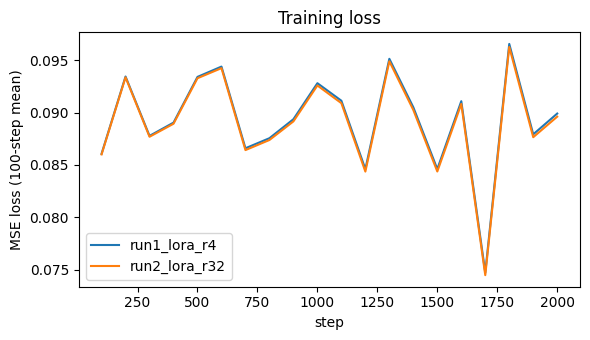

In [9]:
plt.figure(figsize=(6, 3.5))
for name, s in TRAIN.items():
    xs, ys = zip(*s["loss_log"]); plt.plot(xs, ys, label=name)
plt.xlabel("step"); plt.ylabel("MSE loss (100-step mean)"); plt.legend(); plt.title("Training loss"); plt.tight_layout()
plt.savefig(EVAL / "loss_curves.png", dpi=150); plt.show()

## 3. Image generation (Task 2.3)
20 prompts x seeds {0, 1} x {base, run1, run2} = 120 images, same sampler (DPM-Solver++, 30 steps, CFG 7.5, 512x512).
The pipeline is loaded **without** its built-in safety checker so that images are kept; the SD safety checker is then run
separately on every output and the flags are recorded (NSFW filter for the safety analysis).

In [10]:
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor

pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, safety_checker=None,
                                               requires_safety_checker=False).to(DEV)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
checker = StableDiffusionSafetyChecker.from_pretrained(BASE_MODEL, subfolder="safety_checker", torch_dtype=torch.float16).to(DEV)
fe = CLIPImageProcessor.from_pretrained(BASE_MODEL, subfolder="feature_extractor")

def nsfw_flags(pils):
    px = fe(pils, return_tensors="pt").pixel_values.to(DEV, torch.float16)
    arr = np.stack([np.asarray(p, dtype=np.float32) / 255.0 for p in pils])
    _, flags = checker(clip_input=px, images=arr.copy())
    return [bool(f) for f in flags]

MODELS = ["base"] + list(RUNS)
meta = []; GEN_SECONDS = {}
for model in MODELS:
    if model != "base": pipe.load_lora_weights(str(ADAPTERS / model))
    (IMAGES / model).mkdir(parents=True, exist_ok=True)
    torch.cuda.synchronize(); t0 = time.time(); n = 0
    for pr in PROMPTS:
        for seed in SEEDS:
            fn = IMAGES / model / f"p{pr['id']:02d}_s{seed}.png"
            img = pipe(pr["prompt"], num_inference_steps=GEN_STEPS, guidance_scale=GEN_CFG, height=RES, width=RES,
                       generator=torch.Generator(DEV).manual_seed(seed)).images[0]
            img.save(fn); n += 1
            meta.append({"model": model, "prompt_id": pr["id"], "category": pr["category"], "prompt": pr["prompt"],
                         "seed": seed, "file": str(fn.relative_to(WORK))})
    torch.cuda.synchronize(); GEN_SECONDS[model] = round((time.time() - t0) / n, 2)
    if model != "base": pipe.unload_lora_weights()
meta_df = pd.DataFrame(meta)
meta_df["nsfw_flag"] = False
for model in MODELS:
    m = meta_df.model == model
    meta_df.loc[m, "nsfw_flag"] = nsfw_flags([Image.open(WORK / f) for f in meta_df.loc[m, "file"]])
meta_df.to_json(IMAGES / "metadata.jsonl", orient="records", lines=True)
print(meta_df.groupby("model").size().to_dict(), "images generated")
print("Seconds per image:", GEN_SECONDS)
print("NSFW-flagged outputs per model:\n", meta_df.groupby("model").nsfw_flag.sum().to_string())

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

safety_checker/model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


{'base': 40, 'run1_lora_r4': 40, 'run2_lora_r32': 40} images generated
Seconds per image: {'base': 5.58, 'run1_lora_r4': 5.77, 'run2_lora_r32': 5.8}
NSFW-flagged outputs per model:
 model
base             0
run1_lora_r4     3
run2_lora_r32    9


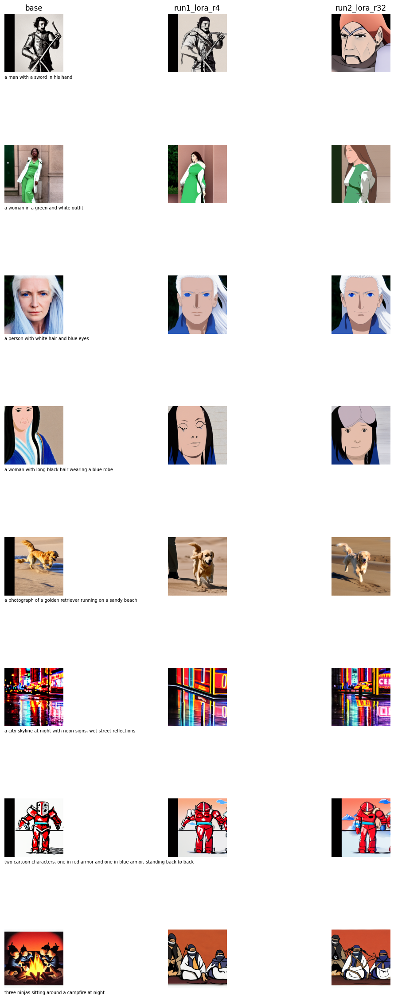

In [11]:
def load_img(model, pid, seed): return Image.open(IMAGES / model / f"p{pid:02d}_s{seed}.png")

# 8 prompts for the side-by-side grid: 4 in-domain, 2 out-of-domain, 2 compositional
GRID_IDS = [0, 1, 2, 3, 10, 12, 15, 17]
fig, axes = plt.subplots(len(GRID_IDS), 3, figsize=(9, 3 * len(GRID_IDS)))
for r, pid in enumerate(GRID_IDS):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]; ax.imshow(load_img(model, pid, 0)); ax.axis("off")
        if r == 0: ax.set_title(model)
    axes[r, 0].text(0, -0.04, PROMPTS[pid]["prompt"][:90], transform=axes[r, 0].transAxes, fontsize=7, va="top")
plt.tight_layout(); plt.savefig(EVAL / "grid_base_vs_runs.png", dpi=130); plt.show()

## 4. Evaluation (Task 2.4)
* **KID** (primary, lower is better): in-domain generations (10 prompts x 2 seeds = 20 images) vs the held-out test images. With only
  20 generated images KID is noisy; the +/- is the std over 100 random subsets (subset size 20 on the generated side, random 20 of the real set).
* **CLIP score** (primary): 100 x cosine(CLIP image, CLIP text) with `openai/clip-vit-base-patch32`, averaged over prompts and seeds.
* **Diversity** (secondary): mean LPIPS(AlexNet) between seed 0 and seed 1 of the same prompt.
* **Efficiency**: GPU-hours and peak memory per training run (section 2).

In [13]:
from torchmetrics.image.kid import KernelInceptionDistance
from transformers import CLIPModel, CLIPProcessor
import lpips

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEV).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def clip_img_emb(pils, bs=64):
    out = []
    for i in range(0, len(pils), bs):
        px = clip_proc(images=pils[i:i + bs], return_tensors="pt").pixel_values.to(DEV)
        out.append(F.normalize(clip.get_image_features(pixel_values=px), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_txt_emb(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        tk = clip_proc(text=texts[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEV)
        out.append(F.normalize(clip.get_text_features(**tk), dim=-1).cpu())
    return torch.cat(out)

def to_u8(pils): return torch.stack([torch.from_numpy(np.array(p.convert("RGB").resize((RES, RES)))).permute(2, 0, 1) for p in pils])

real_u8 = to_u8(test_imgs)
lp = lpips.LPIPS(net="alex").to(DEV).eval()
def lp_t(p): return (torch.from_numpy(np.asarray(p.convert("RGB"), dtype=np.float32) / 127.5 - 1).permute(2, 0, 1)[None]).to(DEV)

rows = {}
for model in MODELS:
    d = meta_df[meta_df.model == model].copy()
    imgs = [Image.open(WORK / f) for f in d.file]
    d["clip_sc"] = (100 * (clip_img_emb(imgs) * clip_txt_emb(d.prompt.tolist())).sum(-1)).clamp(min=0).numpy()
    ind = d[d.category == "in_domain"]
    kid = KernelInceptionDistance(subset_size=min(len(ind), len(test_imgs)), subsets=100, feature=2048).to(DEV)
    kid.update(real_u8.to(DEV), real=True); kid.update(to_u8([Image.open(WORK / f) for f in ind.file]).to(DEV), real=False)
    km, ks = kid.compute()
    div = {}
    for cat, g in d.groupby("category"):
        vals = []
        for pid, gg in g.groupby("prompt_id"):
            a, b = [Image.open(WORK / f) for f in gg.sort_values("seed").file]
            with torch.no_grad(): vals.append(lp(lp_t(a), lp_t(b)).item())
        div[cat] = float(np.mean(vals))
    rows[model] = {"KID_in_domain (lower better)": round(km.item(), 4), "KID_std": round(ks.item(), 4),
                   "CLIP_score_all": round(d.clip_sc.mean(), 2),
                   "CLIP_in_domain": round(d[d.category == "in_domain"].clip_sc.mean(), 2),
                   "CLIP_out_of_domain": round(d[d.category == "out_of_domain"].clip_sc.mean(), 2),
                   "CLIP_compositional": round(d[d.category == "compositional"].clip_sc.mean(), 2),
                   "LPIPS_diversity_all": round(float(np.mean(list(div.values()))), 4),
                   "LPIPS_in_domain": round(div["in_domain"], 4),
                   "NSFW_flagged": int(d.nsfw_flag.sum()), "gen_seconds_per_image": GEN_SECONDS[model]}
    meta_df.loc[d.index, "clip_score"] = d.clip_sc.values
    del kid; gc.collect(); torch.cuda.empty_cache()

results = pd.DataFrame(rows).T
for name in RUNS:
    results.loc[name, "train_GPU_hours"] = TRAIN[name]["gpu_hours"]
    results.loc[name, "peak_mem_GB"] = TRAIN[name]["peak_mem_allocated_gb"]
    results.loc[name, "trainable_params"] = TRAIN[name]["trainable_params"]
print(results.T.to_string())
results.to_csv(EVAL / "p2_results.csv"); results.to_json(EVAL / "p2_results.json", indent=2)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028


                                   base   run1_lora_r4  run2_lora_r32
KID_in_domain (lower better)   0.107700       0.048300   1.340000e-02
KID_std                        0.013600       0.008800   5.600000e-03
CLIP_score_all                32.240002      31.350000   3.071000e+01
CLIP_in_domain                31.030001      29.730000   2.832000e+01
CLIP_out_of_domain            33.849998      33.150002   3.367000e+01
CLIP_compositional            33.060001      32.790001   3.252000e+01
LPIPS_diversity_all            0.808800       0.780700   7.514000e-01
LPIPS_in_domain                0.841600       0.797100   7.524000e-01
NSFW_flagged                   0.000000       3.000000   9.000000e+00
gen_seconds_per_image          5.580000       5.770000   5.800000e+00
train_GPU_hours                     NaN       0.696000   6.950000e-01
peak_mem_GB                         NaN       2.860000   2.930000e+00
trainable_params                    NaN  797184.000000   6.377472e+06


## 5. Choose the final run
Default rule: lower in-domain KID wins. Read the grids and the numbers above, then override `FINAL_RUN` (and explain why in the
report / markdown below) if your judgement differs - e.g. if the higher rank overfits or ignores prompts on out-of-domain inputs.

In [14]:
FINAL_RUN = min(RUNS, key=lambda r: results.loc[r, "KID_in_domain (lower better)"])
# FINAL_RUN = "run2_lora_r32"   # <- manual override
print("Selected final run:", FINAL_RUN)
print(results.loc[["base", *RUNS], ["KID_in_domain (lower better)", "CLIP_score_all", "LPIPS_diversity_all"]].to_string())

Selected final run: run2_lora_r32
               KID_in_domain (lower better)  CLIP_score_all  LPIPS_diversity_all
base                                 0.1077       32.240002               0.8088
run1_lora_r4                         0.0483       31.350000               0.7807
run2_lora_r32                        0.0134       30.709999               0.7514


## 6. Blinded human evaluation (final run vs base, 25 pairs)
`human_eval/pair_XX.png` shows two images side by side (left/right randomised, no labels). Give the folder and the sheet to
**at least 3 raters (both members + one person outside the team)**. Each rater fills `human_eval/ratings/<name>.csv` with columns
`pair_id,choice` where choice is `L` or `R` (the image with better domain style AND prompt match). Re-run the analysis cell afterwards.
The answer key stays in `human_eval/key.json` (do not share).

In [15]:
rng = np.random.RandomState(266)
cand = [(pid, s) for pid in range(20) for s in SEEDS]
pairs = [cand[i] for i in rng.choice(len(cand), 25, replace=False)]
key = []
(HUMAN / "ratings").mkdir(exist_ok=True)
for k, (pid, s) in enumerate(pairs, 1):
    final_left = bool(rng.randint(0, 2))
    a, b = load_img(FINAL_RUN, pid, s), load_img("base", pid, s)
    left, right = (a, b) if final_left else (b, a)
    canvas = Image.new("RGB", (RES * 2 + 8, RES), "white"); canvas.paste(left, (0, 0)); canvas.paste(right, (RES + 8, 0))
    canvas.save(HUMAN / f"pair_{k:02d}.png")
    key.append({"pair_id": k, "prompt_id": pid, "seed": s, "prompt": PROMPTS[pid]["prompt"], "final_side": "L" if final_left else "R"})
(HUMAN / "key.json").write_text(json.dumps(key, indent=2))
pd.DataFrame({"pair_id": range(1, 26), "prompt": [x["prompt"] for x in key], "choice": ""}).to_csv(HUMAN / "rating_sheet_template.csv", index=False)
print("Created 25 blinded pairs in", HUMAN)

Created 25 blinded pairs in /kaggle/working/human_eval


In [23]:
RATINGS = {
    "evaluator1": "LRLLLLLLLRRLLLLRRLLRLLLLL",
    "evaluator2": "LRRLLLRLRRRLRLLRRLLLLLLLL",
    "evaluator3": "LRRLLLLLLLRLLLLRRLLRLLLLL",
}
(HUMAN / "ratings").mkdir(exist_ok=True)
for name, s in RATINGS.items():
    assert len(s) == 25 and set(s) <= {"L", "R"}
    pd.DataFrame({"pair_id": range(1, 26), "choice": list(s)}).to_csv(HUMAN / "ratings" / f"{name}.csv", index=False)
print("wrote", sorted(p.name for p in (HUMAN / "ratings").glob("*.csv")))

wrote ['evaluator1.csv', 'evaluator2.csv', 'evaluator3.csv']


In [24]:
# Human-evaluation analysis: runs only on real rater files.
files = sorted((HUMAN / "ratings").glob("*.csv"))
key_df = pd.DataFrame(json.loads((HUMAN / "key.json").read_text())).set_index("pair_id")
if len(files) < 3:
    print(f"Found {len(files)} rater file(s) in {HUMAN/'ratings'}; need >= 3 (both members + 1 outsider). No win rate computed yet.")
    HUMAN_RESULT = None
else:
    votes = {}
    for f in files:
        r = pd.read_csv(f).dropna(subset=["choice"]); r["choice"] = r.choice.str.strip().str.upper()
        votes[f.stem] = {int(p): (c == key_df.loc[int(p), "final_side"]) for p, c in zip(r.pair_id, r.choice)}  # True = final run won
    V = pd.DataFrame(votes).sort_index()
    per_rater = V.mean(); overall = float(V.stack().mean())
    majority = (V.mean(axis=1) > 0.5).mean()
    agree = np.mean([(V[a] == V[b]).mean() for i, a in enumerate(V) for b in list(V)[i + 1:]])
    HUMAN_RESULT = {"raters": list(V.columns), "win_rate_final_vs_base": round(overall, 3),
                    "per_rater_win_rate": per_rater.round(3).to_dict(), "majority_vote_win_rate": round(float(majority), 3),
                    "mean_pairwise_agreement": round(float(agree), 3)}
    print(json.dumps(HUMAN_RESULT, indent=2))
    (EVAL / "human_eval_result.json").write_text(json.dumps(HUMAN_RESULT, indent=2))

{
  "raters": [
    "evaluator1",
    "evaluator2",
    "evaluator3"
  ],
  "win_rate_final_vs_base": 0.293,
  "per_rater_win_rate": {
    "evaluator1": 0.28,
    "evaluator2": 0.24,
    "evaluator3": 0.36
  },
  "majority_vote_win_rate": 0.32,
  "mean_pairwise_agreement": 0.84
}


In [26]:
cat = key_df.prompt_id.map(lambda i: PROMPTS[i]["category"])
print("Final-run win rate by prompt category (mean over 3 raters), with number of pairs:")
print(V.mean(axis=1).groupby(cat).agg(["mean", "count"]).round(3).to_string())
L_rate = {n: round(float((pd.read_csv(HUMAN / "ratings" / f"{n}.csv").choice == "L").mean()), 2) for n in RATINGS}
print("Share of 'L' picks per rater:", L_rate)
print("Share of pairs where the final run was on the right:", round(float((key_df.final_side == "R").mean()), 2))

Final-run win rate by prompt category (mean over 3 raters), with number of pairs:
                mean  count
prompt_id                  
compositional  0.375      8
in_domain      0.238     14
out_of_domain  0.333      3
Share of 'L' picks per rater: {'evaluator1': 0.76, 'evaluator2': 0.64, 'evaluator3': 0.76}
Share of pairs where the final run was on the right: 0.64


In [25]:
DATA_LICENSE = "not stated on the dataset card (copyrighted anime frames: treat as non-commercial research use only)"

## 7. Failure modes (Task 2.4.1)
The cell below shows, for every out-of-domain and compositional prompt, base vs run1 vs run2 (seed 0), plus both seeds of the
in-domain prompts for the final run (to look for repeated outputs / overfitting). **After looking at them, write at least two failure
modes in the markdown cell below** (e.g. "run2 renders the golden retriever as an anime character = domain bleed / ignores the prompt";
"compositional prompt gets one character, not two"; "seeds 0 and 1 look near-identical = low diversity").

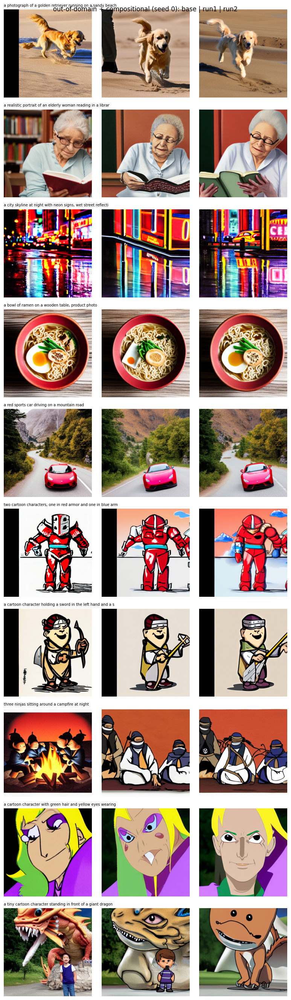

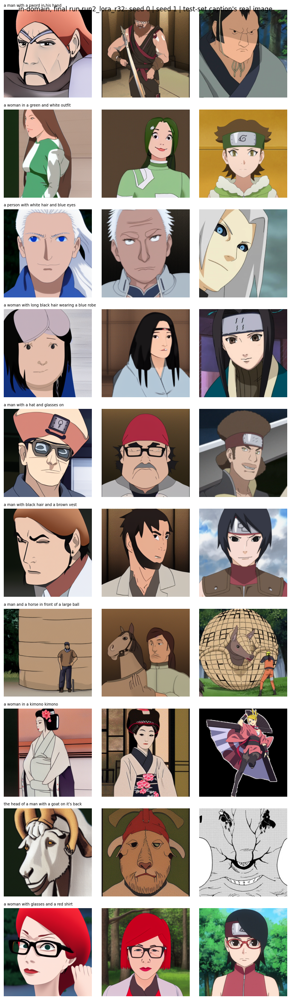

In [17]:
for ids, title in [(range(10, 20), "out-of-domain + compositional (seed 0): base | run1 | run2"),
                   (range(0, 10), f"in-domain, final run {FINAL_RUN}: seed 0 | seed 1 | test-set caption's real image")]:
    ids = list(ids); ncol = 3
    fig, axes = plt.subplots(len(ids), ncol, figsize=(8, 2.7 * len(ids)))
    for r, pid in enumerate(ids):
        for c in range(ncol):
            ax = axes[r, c]; ax.axis("off")
            if "out-of-domain" in title: ax.imshow(load_img(MODELS[c], pid, 0))
            elif c < 2: ax.imshow(load_img(FINAL_RUN, pid, c))
            else:
                j = test_caps.index(PROMPTS[pid]["prompt"]); ax.imshow(test_imgs[j])
        axes[r, 0].set_title(PROMPTS[pid]["prompt"][:60], fontsize=7, loc="left")
    fig.suptitle(title); plt.tight_layout(); plt.show()

**Failure modes (from the grids above, prompt ids refer to the fixed prompt list):**

1. **Compositional prompts are not followed (prompts 15, 16 and 18).** For "two cartoon characters, one in red armor and one in blue armor" (prompt 15), the base model and both runs draw one red armored figure, and the second (blue) character is missing or cut off at the right edge. For "a sword in the left hand and a scroll in the right hand" (prompt 16), all three models draw one character with a weapon but no scroll. For "green hair and yellow eyes wearing a purple cloak" (prompt 18), run 2 gives yellow hair with green only on the eyebrows and clothes, while the base model and run 1 keep green in the hair. Fine-tuning on short captions did not teach multi-object or multi-attribute composition.
2. **Prompt ignored and domain bleed on an out-of-domain prompt (prompt 19).** For "a tiny cartoon character standing in front of a giant dragon", the base model draws a child in front of a dragon statue, run 1 keeps the child but loses most of the dragon, and run 2 draws a single brown cartoon animal with no dragon and no small character. A higher rank pulls out-of-domain prompts further toward the anime look and away from the prompt.
3. **Lower diversity (all prompts).** Average LPIPS between the two seeds falls from 0.809 (base) to 0.781 (r=4) and 0.751 (r=32), so the fine-tuned models produce more similar images across seeds, with r=32 the least varied.
4. **Rendering artifact (several prompts, base model included).** Some images have a black bar on the left edge (for example prompts 10, 15 and 16). It also appears in the base model, so fine-tuning did not cause it.

**NSFW filter review.** The safety checker flagged 0 of 40 base images, 3 of 40 from r=4 and 9 of 40 from r=32. We reviewed all 12 flagged images by eye (see `eval/nsfw_flagged.png`): all show clothed anime characters, mostly close-up portraits with large flat skin-toned regions, and none contains explicit content. We treat them as likely false positives from a checker designed for photographs.

**Human evaluation (final run r=32 vs base, 25 blinded pairs, 3 raters including one outside the team):** the final run won 29.3% of ratings (per rater 28%, 24% and 36%; majority-vote win rate 32%), so raters preferred the base model more often than the fine-tuned model. Mean pairwise agreement was 0.84. Raters chose the left image in a large majority of pairs, while the fine-tuned model was on the right in 16 of the 25 pairs, so position bias probably lowered its win rate. The pairs also mix in-domain, out-of-domain and compositional prompts, where a base-model photo can reasonably win on prompt match, so this single number does not say how well the model does on the in-domain task by itself.

**Run chosen and why:** run 2 (LoRA r=32). It is by far the closest to the held-out test images (KID 0.0134 vs 0.0483 for r=4 and 0.1077 for the base model) and gives the most consistent Naruto style on in-domain prompts. The costs are the lowest CLIP score (30.71 vs 31.35 for r=4 and 32.24 for the base model), the lowest diversity (LPIPS 0.751), more NSFW-filter flags (likely false positives), more prompt-ignoring on out-of-domain and compositional prompts (failure modes 1 and 2), and a human win rate below 50% against the base model. We chose style fidelity, since the task is domain-specific generation. If prompt alignment mattered more, r=4 would be the safer choice.

#

Dataset license: not stated on the dataset card (copyrighted anime frames: treat as non-commercial research use only) (non-commercial research use only; the characters are copyrighted).
Base model license: CreativeML OpenRAIL-M.

NSFW filter = Stable Diffusion safety checker, run on all 120 outputs:
               flagged  total
model                        
base                 0     40
run1_lora_r4         3     40
run2_lora_r32        9     40

Nearest-training-image similarity for 10 in-domain generations:
  prompt_id  nearest_train_idx  clip_cosine
         0                527       0.9024
         1                714       0.8055
         2                411       0.8858
         3                462       0.8723
         4                258       0.8895
         5                794       0.9048
         6                844       0.7448
         7               1055       0.7715
         8                206       0.7616
         9                714       0.7662
Reference:

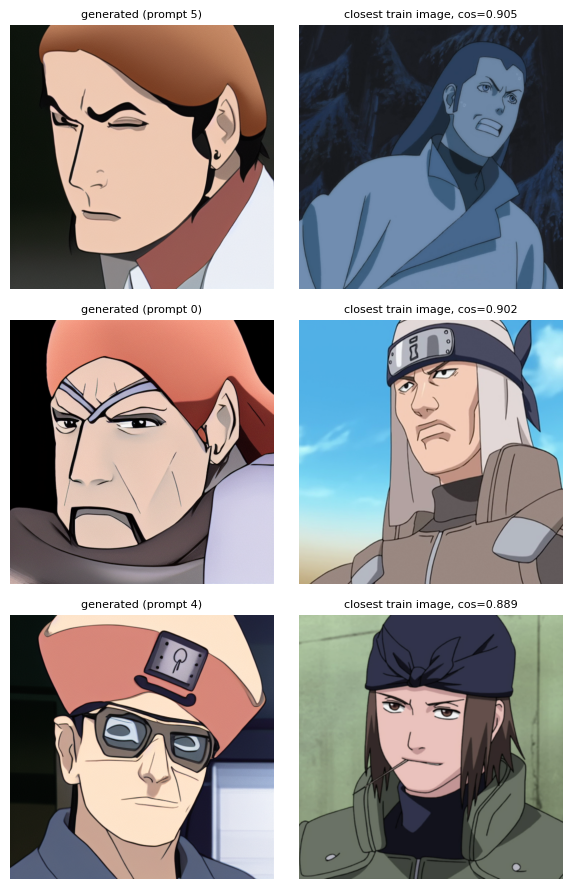

In [27]:
print("Dataset license:", DATA_LICENSE, "(non-commercial research use only; the characters are copyrighted).")
print("Base model license: CreativeML OpenRAIL-M.")
print("\nNSFW filter = Stable Diffusion safety checker, run on all", len(meta_df), "outputs:")
print(meta_df.groupby("model").nsfw_flag.agg(["sum", "count"]).rename(columns={"sum": "flagged", "count": "total"}).to_string())

# Memorization: 10 in-domain images from the FINAL run (seed 0) -> nearest TRAIN image by CLIP image similarity.
gen_sel = [load_img(FINAL_RUN, pid, 0) for pid in range(10)]
sim = clip_img_emb(gen_sel) @ clip_img_emb(train_imgs).T
top_sim, top_idx = sim.max(dim=1)
mem_df = pd.DataFrame({"prompt_id": range(10), "nearest_train_idx": top_idx.numpy(), "clip_cosine": top_sim.numpy().round(4)})
print("\nNearest-training-image similarity for 10 in-domain generations:\n", mem_df.to_string(index=False))
# Reference: how similar are real TEST images to their nearest train image? (puts the numbers in context)
ref = (clip_img_emb(test_imgs) @ clip_img_emb(train_imgs).T).max(dim=1).values
print(f"Reference: test image -> nearest train image: mean cos {ref.mean():.3f}, max {ref.max():.3f}")
mem_df.to_csv(EVAL / "memorization_check.csv", index=False)

order = top_sim.argsort(descending=True)[:3].tolist()
fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for r, o in enumerate(order):
    axes[r, 0].imshow(gen_sel[o]); axes[r, 0].set_title(f"generated (prompt {o})", fontsize=8)
    axes[r, 1].imshow(train_imgs[top_idx[o].item()]); axes[r, 1].set_title(f"closest train image, cos={top_sim[o]:.3f}", fontsize=8)
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout(); plt.savefig(EVAL / "memorization_top3.png", dpi=130); plt.show()

model          category     
run1_lora_r4   in_domain        3
run2_lora_r32  compositional    2
               in_domain        7
dtype: int64


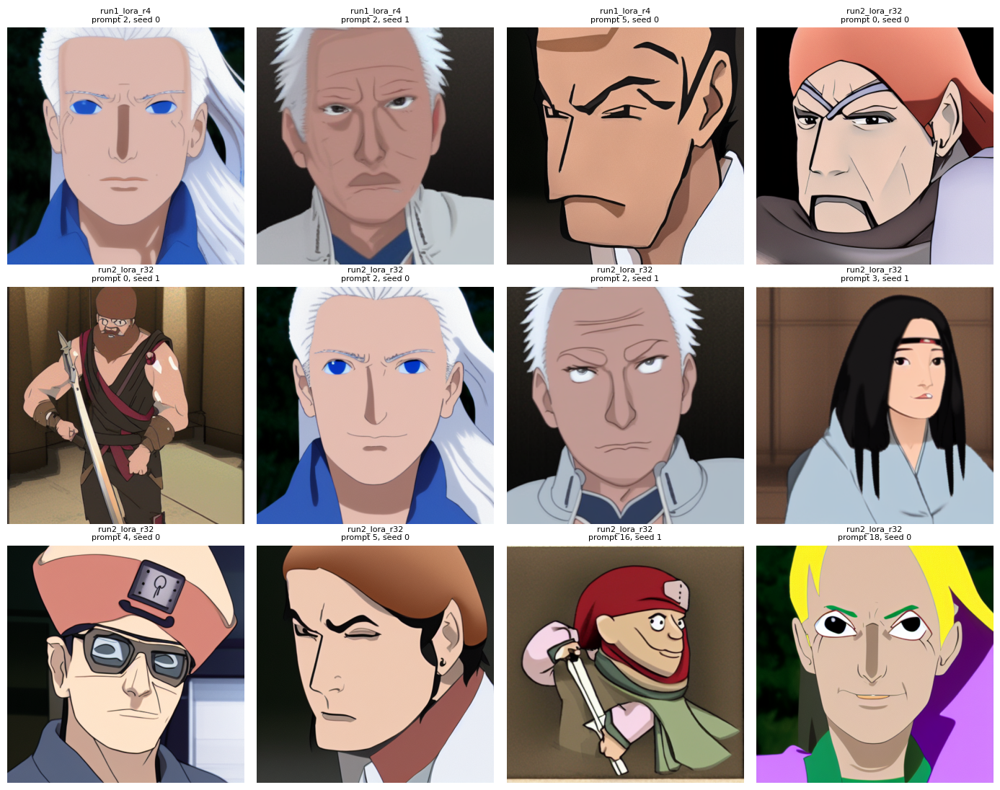

In [21]:
flagged = meta_df[meta_df.nsfw_flag].sort_values(["model", "prompt_id"])
print(flagged.groupby(["model", "category"]).size())
fig, ax = plt.subplots(3, 4, figsize=(14, 11))
for a, (_, r) in zip(ax.flat, flagged.iterrows()):
    a.imshow(Image.open(WORK / r.file))
    a.set_title(f"{r.model}\nprompt {r.prompt_id}, seed {r.seed}", fontsize=8)
    a.axis("off")
plt.tight_layout(); plt.savefig(EVAL / "nsfw_flagged.png", dpi=120); plt.show()

**NSFW filter review (all 12 flagged images):**
We ran the Stable Diffusion safety checker on all 120 generated images. It flagged 0 of 40 base-model images, 3 of 40 from the rank-4 LoRA and 9 of 40 from the rank-32 LoRA. We reviewed all 12 flagged images by eye. All show clothed anime characters, mostly close-up portraits with large flat skin-toned regions, and none contains explicit content. We therefore treat them as likely false positives from a checker designed for photographs, not as unsafe outputs. Images were not blacked out, so the quality metrics are unaffected. Because the filter can misfire on this art style, it should not be relied on alone for deployment. The model is released for non-commercial research use only, as the training data are copyrighted anime frames and the dataset card states no license.

## 9. Push models, model card and images to Hugging Face
Needs `HF_USER` set and an `HF_TOKEN` secret (write access). Weights and images go to Hugging Face, never to GitHub.

In [19]:
def model_card(final):
    s = TRAIN[final]; r = results.loc[final]; b = results.loc["base"]
    hw = f"{HUMAN_RESULT['win_rate_final_vs_base']:.0%} win rate vs base ({len(HUMAN_RESULT['raters'])} raters)" if HUMAN_RESULT else "not yet run"
    return f"""---
license: creativeml-openrail-m
base_model: {BASE_MODEL}
datasets: [{DATASET}]
tags: [stable-diffusion, text-to-image, lora, diffusers, naruto]
---
# {HF_USER}/naruto-sd15-{final}

LoRA adapter (`{s['method']}`) for Stable Diffusion 1.5 that generates Naruto-style anime images. Load with
`pipe.load_lora_weights("{HF_USER}/naruto-sd15-{final}")`.

**Data.** `{DATASET}`, {len(train_imgs)} training images after removing {corrupted} corrupted and {exact_dups + near_dups} duplicate images
(90/10 split, seed 266). Dataset license: {DATA_LICENSE}.
**Training.** {STEPS} steps, batch {BATCH}, LR {LR} (cosine, {WARMUP} warmup), AdamW, fp16 + gradient checkpointing, rank {s['rank']} on attention
projections, {s['trainable_params']:,} trainable parameters, peak GPU memory {s['peak_mem_allocated_gb']} GB, {s['gpu_hours']} GPU-hours (seed 266).
**Results** (20 fixed prompts, seeds 0/1, vs base): in-domain KID {r['KID_in_domain (lower better)']} (base {b['KID_in_domain (lower better)']}), CLIP score
{r['CLIP_score_all']} (base {b['CLIP_score_all']}), LPIPS diversity {r['LPIPS_diversity_all']} (base {b['LPIPS_diversity_all']}); human evaluation: {hw}.
**Limitations.** Narrow style and cast; out-of-domain prompts are pulled toward the anime look; machine-made captions; small test set makes KID noisy;
possible resemblance to training frames (see memorization check in the notebook).
**License / intended use.** Trained on copyrighted anime frames: non-commercial research use only. CreativeML OpenRAIL-M applies to the base model.
"""

if HF_TOKEN and HF_USER != "YOUR_HF_USERNAME":
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    for name in RUNS:
        repo = f"{HF_USER}/naruto-sd15-{name}"
        api.create_repo(repo, exist_ok=True)
        if name == FINAL_RUN: (ADAPTERS / name / "README.md").write_text(model_card(name))
        api.upload_folder(folder_path=str(ADAPTERS / name), repo_id=repo)
        print("pushed", repo)
else:
    print("Skipped upload: set HF_USER and the HF_TOKEN secret.")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

pushed rohil542/naruto-sd15-run1_lora_r4


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

pushed rohil542/naruto-sd15-run2_lora_r32


In [20]:
if HF_TOKEN and HF_USER != "YOUR_HF_USERNAME":
    from datasets import Dataset, Features, Value, Image as HFImg
    d = meta_df[["model", "prompt_id", "category", "prompt", "seed", "file", "nsfw_flag", "clip_score"]].copy()
    d["image"] = [str(WORK / f) for f in d.file]
    ds = Dataset.from_pandas(d.drop(columns="file"), preserve_index=False).cast_column("image", HFImg())
    ds.push_to_hub(f"{HF_USER}/naruto-sd15-generations", token=HF_TOKEN)
    print("pushed dataset", f"{HF_USER}/naruto-sd15-generations", len(ds), "rows")
else:
    print("Skipped upload: set HF_USER and the HF_TOKEN secret.")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


pushed dataset rohil542/naruto-sd15-generations 120 rows


#

In [28]:
print(results.T.to_string())
print("\nFinal run:", FINAL_RUN, "| Human evaluation:", HUMAN_RESULT if HUMAN_RESULT else "pending - collect >=3 rater CSVs, then re-run section 6 analysis")

                                   base   run1_lora_r4  run2_lora_r32
KID_in_domain (lower better)   0.107700       0.048300   1.340000e-02
KID_std                        0.013600       0.008800   5.600000e-03
CLIP_score_all                32.240002      31.350000   3.071000e+01
CLIP_in_domain                31.030001      29.730000   2.832000e+01
CLIP_out_of_domain            33.849998      33.150002   3.367000e+01
CLIP_compositional            33.060001      32.790001   3.252000e+01
LPIPS_diversity_all            0.808800       0.780700   7.514000e-01
LPIPS_in_domain                0.841600       0.797100   7.524000e-01
NSFW_flagged                   0.000000       3.000000   9.000000e+00
gen_seconds_per_image          5.580000       5.770000   5.800000e+00
train_GPU_hours                     NaN       0.696000   6.950000e-01
peak_mem_GB                         NaN       2.860000   2.930000e+00
trainable_params                    NaN  797184.000000   6.377472e+06

Final run: run2_lor

In [29]:
import shutil, os
from IPython.display import FileLink, display
# zip all of /kaggle/working into one file stored outside it, so the zip doesn't include itself
shutil.make_archive("/tmp/part2_all", "zip", "/kaggle/working")
shutil.move("/tmp/part2_all.zip", "/kaggle/working/part2_all.zip")
print(round(os.path.getsize("/kaggle/working/part2_all.zip") / 1e6, 1), "MB")
display(FileLink("part2_all.zip"))

207.7 MB


/kaggle/working/part2_all.zip